**ANOMALY DETECTION OC-SVM**

In [11]:
import digitalhub as dh
import zipfile
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

PROJECT_NAME = "floods"
project = dh.get_project(PROJECT_NAME)
print(f"Project: {project.name}")

Project: floods


**SETUP PARAMETERS**

In [24]:
job_name = "net_v5_msPre_pool16_vec"

parameters = {
    "job_name": job_name,
    "vectors_from": "net_v5_msPre_pool16_vec",                 
    "punti": "pre_proj, encoder_fine",
    "distanze": "coseno, lw",
    "ks": "1, 2, 5, 10, 20"
}

volumes = [
    {
        "volume_type": "ephemeral",
        "name": "volume-spazio-dati",
        "mount_path": "/data",
        "spec": {"size": "20Gi"}
    }
]

**BUILD ENVIRONMENT**

In [25]:
ocsvm_func = project.new_function(
    name=f'ad_knn_{job_name}',
    kind="python",
    python_version="PYTHON3_10",
    code_src="../../src/",
    handler="anomaly_punti:ad_knn",
    image="harbor.atlas.fbk.eu/rsde/rsde-platform-floods-floodsimagev3:9b7e2",
)

**TRAINING**

In [26]:
resources = {"cpu": "4", "mem": "20Gi"}

run_ad = ocsvm_func.run(
    action="job",
    parameters=parameters,
    volumes=volumes,
    resources = resources,
    profile="1xv100",
    local_execution=False,
    wait=True
)

print(f"Run anomaly detection knn: {run_ad.id}")

2026-11-13 08:24:21,822 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 3c949399bf8d492f9094f1df0da90876 to finish...


2026-11-13 08:24:26,829 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 3c949399bf8d492f9094f1df0da90876 to finish...
2026-11-13 08:24:31,841 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 3c949399bf8d492f9094f1df0da90876 to finish...
2026-11-13 08:24:36,853 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 3c949399bf8d492f9094f1df0da90876 to finish...
2026-11-13 08:24:41,867 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 3c949399bf8d492f9094f1df0da90876 to finish...
2026-11-13 08:24:46,877 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 3c949399bf8d492f9094f1df0da90876 to finish...
2026-11-13 08:24:51,890 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 3c949399bf8d492f9094f1df0da90876 to finish...


BackendError: Not found. Response: {"status":404,"message":"No such run.","errorCode":null}.

In [ ]:
import os, json, shutil, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import rankdata, spearmanr
from sklearn.metrics import roc_auc_score, roc_curve

K = 1
FAS = (0.05, 0.10, 0.15, 0.20, 0.25, 0.30)

def scarica(nome_artifact, cartella):
    shutil.rmtree(cartella, ignore_errors=True)
    zp = project.get_artifact(nome_artifact).download(f"{cartella}.zip", overwrite=True)
    with zipfile.ZipFile(zp) as z:
        z.extractall(cartella)

RESULTS_DIR = f"/tmp/anomaly_results_knn_{job_name}"
scarica(f"anomaly_results_knn_{job_name}", RESULTS_DIR)

with open(f"{RESULTS_DIR}/summary.json") as f:
    summary = json.load(f)
job_ocsvm = summary["vectors_from"]                       
OCSVM_DIR = f"/tmp/anomaly_results_ocsvm_{job_ocsvm}"
scarica(f"anomaly_results_ocsvm_{job_ocsvm}", OCSVM_DIR)

ha_ms = os.path.exists(f"{RESULTS_DIR}/pre_proj_ms/coseno/scores.csv")   
print(f"knn: {job_name} | ocsvm: {job_ocsvm} | moco: {summary['moco_version']} | pre_proj_ms: {ha_ms}")

knn: net_v5_msPre_pool16_vec | ocsvm: net_v5_msPre_pool16_vec | moco: net_v5_msPre | pre_proj_ms: False


In [ ]:
def leggi(punto, distanza, k=K):
    """Restituisce (df test, ID normali di soglia, score normali di soglia, score test). Più alto = più anomalo."""
    if distanza == "ocsvm":
        test = pd.read_csv(f"{OCSVM_DIR}/{punto}/scores.csv")
        thr = pd.read_csv(f"{OCSVM_DIR}/{punto}/scores_thr.csv")
        return test, thr["ID"].values, -thr["score"].values, -test["score"].values
    test = pd.read_csv(f"{RESULTS_DIR}/{punto}/{distanza}/scores.csv")
    thr = pd.read_csv(f"{RESULTS_DIR}/{punto}/{distanza}/scores_thr.csv")
    return test, thr["ID"].values, thr[f"score_k{k}"].values, test[f"score_k{k}"].values

def percentile(valori, riferimento):
    """Frazione delle normali di riferimento con score più basso (0 = normalissima, 1 = più anomala di tutte)."""
    return np.searchsorted(np.sort(riferimento), valori, side="right") / len(riferimento)

def rango(s):
    return rankdata(s) / len(s)

def regole(score_cal, score_test, y, fas=FAS):
    """Soglie dalle normali di calibrazione, valutate sul test (anomalia = score sopra la soglia)."""
    s_norm, s_anom = score_test[y == 0], score_test[y == 1]
    out = {}
    for fa in fas:
        soglia = float(np.quantile(score_cal, 1 - fa))
        tp = int((s_anom > soglia).sum()); fn = len(s_anom) - tp
        fp = int((s_norm > soglia).sum()); tn = len(s_norm) - fp
        prec = tp / (tp + fp) if tp + fp else 0.0
        rec = tp / (tp + fn)
        out[f"FA {fa:.0%}"] = {"soglia": soglia, "TP": tp, "FP": fp, "FN": fn, "TN": tn,
                               "FA_rate": fp / (fp + tn), "REC": rec, "PREC": prec,
                               "F1": 2 * prec * rec / (prec + rec) if tp > 0 else 0.0}
    return out

def combina(conf, seed=0):
    """Media dei percentili; normali di soglia divise a metà: riferimento (percentili) / calibrazione (soglie)."""
    nomi = list(conf)
    test0, ids_thr0, thr0, _ = leggi(*conf[nomi[0]])
    y = test0["label"].values
    perm = np.random.default_rng(seed).permutation(len(thr0))
    idx_rif, idx_cal = perm[: len(perm) // 2], perm[len(perm) // 2:]

    p_cal, p_test, grezzi = {}, {}, {}
    for nome in nomi:
        test, ids_thr, s_thr, s_test = leggi(*conf[nome])
        assert (test["ID"].values == test0["ID"].values).all(), f"{nome}: serie di test diverse"
        assert (ids_thr == ids_thr0).all(), f"{nome}: normali di soglia diverse"
        rif = s_thr[idx_rif]
        p_cal[nome] = percentile(s_thr[idx_cal], rif)
        p_test[nome] = percentile(s_test, rif)
        grezzi[nome] = s_test

    score_cal = np.mean(list(p_cal.values()), axis=0)
    score_test = np.mean(list(p_test.values()), axis=0)
    return {"y": y, "nomi": nomi, "p_cal": p_cal, "p_test": p_test, "grezzi": grezzi,
            "score_cal": score_cal, "score_test": score_test,
            "auroc": roc_auc_score(y, score_test), "rules": regole(score_cal, score_test, y)}

def bootstrap_diff(s_a, s_b, y, n_boot=2000, seed=0):
    """Differenza di AUROC (s_a - s_b) sulle stesse serie ricampionate: media e intervallo al 95%."""
    rng = np.random.default_rng(seed)
    diff = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() == y[i].max():
            continue
        diff.append(roc_auc_score(y[i], s_a[i]) - roc_auc_score(y[i], s_b[i]))
    lo, hi = np.percentile(diff, [2.5, 97.5])
    return np.mean(diff), lo, hi

def recall_a_fa(y, score, fas=FAS):
    """Recall letto sulla curva ROC esattamente a quei falsi allarmi (confronto equo tra metodi)."""
    fpr, tpr, _ = roc_curve(y, score)
    return np.interp(fas, fpr, tpr)

def plot_istogramma(ax, score, y, rules, titolo, xlabel):
    s_norm, s_anom = score[y == 0], score[y == 1]
    lo, hi = np.quantile(score, [0.005, 0.995])
    bins = np.linspace(lo, hi, 100)
    ax.hist(s_norm, bins=bins, alpha=0.6, density=True, label=f"normali ({len(s_norm)})")
    ax.hist(s_anom, bins=bins, alpha=0.6, density=True, label=f"anomale ({len(s_anom)})")
    for nome_regola, rr in rules.items():                 # rr, non r: niente più sovrascritture
        if lo <= rr["soglia"] <= hi:
            ax.axvline(rr["soglia"], color="gray", linestyle="--", linewidth=1)
            ax.text(rr["soglia"], ax.get_ylim()[1] * 0.97, nome_regola, rotation=90, va="top", ha="right", fontsize=8)
    ax.set_xlabel(xlabel); ax.set_title(titolo); ax.legend(loc="upper right")

def plot_confusioni(dati):
    """dati = {nome: (rules, auroc)} -> una riga di matrici per configurazione."""
    n_cols = max(len(rules) for rules, _ in dati.values())
    fig = plt.figure(figsize=(4 * n_cols, 4.5 * len(dati)), layout="constrained")
    for sfig, (nome, (rules, auroc)) in zip(np.atleast_1d(fig.subfigures(len(dati), 1)), dati.items()):
        axes_row = sfig.subplots(1, n_cols, squeeze=False)[0]
        for ax, (nome_regola, rr) in zip(axes_row, rules.items()):
            mat = np.array([[rr["TN"], rr["FP"]], [rr["FN"], rr["TP"]]])
            pct = mat / mat.sum(axis=1, keepdims=True) * 100
            ax.imshow(pct, cmap="Blues", vmin=0, vmax=100)
            ax.set_xticks([0, 1]); ax.set_xticklabels(["Normale", "Anomala"])
            ax.set_yticks([0, 1]); ax.set_yticklabels(["Normale", "Anomala"])
            ax.set_xlabel("Predetto"); ax.set_ylabel("Verità"); ax.set_title(nome_regola, fontsize=9)
            for i in range(2):
                for j in range(2):
                    ax.text(j, i, f"{mat[i, j]}\n({pct[i, j]:.1f}%)", ha="center", va="center",
                            color="white" if pct[i, j] > 55 else "black", fontsize=10)
        for ax in axes_row[len(rules):]:
            ax.axis("off")
        sfig.suptitle(f"{nome} | AUROC {auroc:.3f}", fontsize=12, fontweight="bold")
    plt.show()

In [ ]:
tabella = pd.read_csv(f"{RESULTS_DIR}/tabella.csv")             

def rec_fa10(riga):
    with open(f"{RESULTS_DIR}/{riga.punto}/{riga.distanza}/risultati_k{riga.k}.json") as f:
        return json.load(f)["rules"]["FA 10%"]["REC"]

tabella["REC a FA 10%"] = tabella.apply(rec_fa10, axis=1)


for punto, gruppo in tabella.groupby("punto", sort=False):
    print(f"===== {punto} =====")
    for _, r_ in gruppo.iterrows():
        print(f"{r_.punto:11s} | {r_.distanza:6s} | k={r_.k:3d} | AUROC {r_.AUROC:.4f} | "
              f"REC a FA 10% {r_['REC a FA 10%']:.3f}")
    print()


display(tabella.pivot_table(index=["punto", "distanza"], columns="k", values="AUROC").round(3))
#display(tabella.pivot_table(index=["punto", "distanza"], columns="k", values="REC a FA 10%").round(3))


with open(f"{OCSVM_DIR}/summary.json") as f:
    oc = json.load(f)["punti"]


===== pre_proj =====
pre_proj    | coseno | k=  1 | AUROC 0.7500 | REC a FA 10% 0.362
pre_proj    | lw     | k=  1 | AUROC 0.8179 | REC a FA 10% 0.429

===== encoder_fine =====
encoder_fine | coseno | k=  1 | AUROC 0.6043 | REC a FA 10% 0.102
encoder_fine | lw     | k=  1 | AUROC 0.8791 | REC a FA 10% 0.646



k                          1
punto        distanza       
encoder_fine coseno    0.604
             lw        0.879
pre_proj     coseno    0.750
             lw        0.818

scelte: [('pre_proj', 'lw', 1), ('encoder_fine', 'lw', 1)]


,AUROC,REC a FA 10%
configurazione,,
pre_proj | lw | k=1,0.818,0.429
encoder_fine | lw | k=1,0.879,0.646


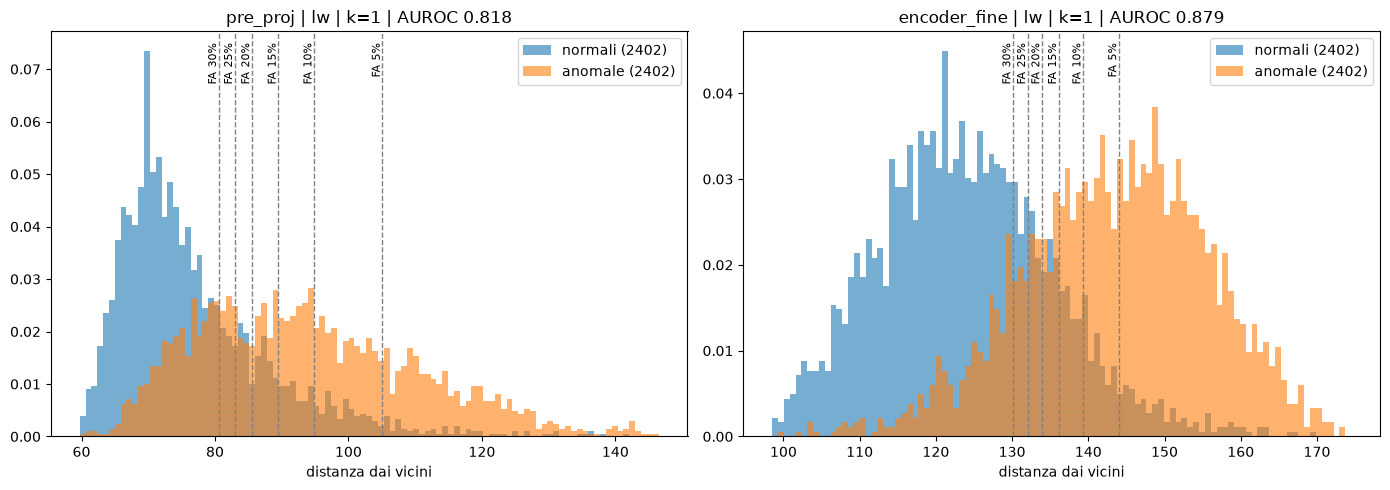

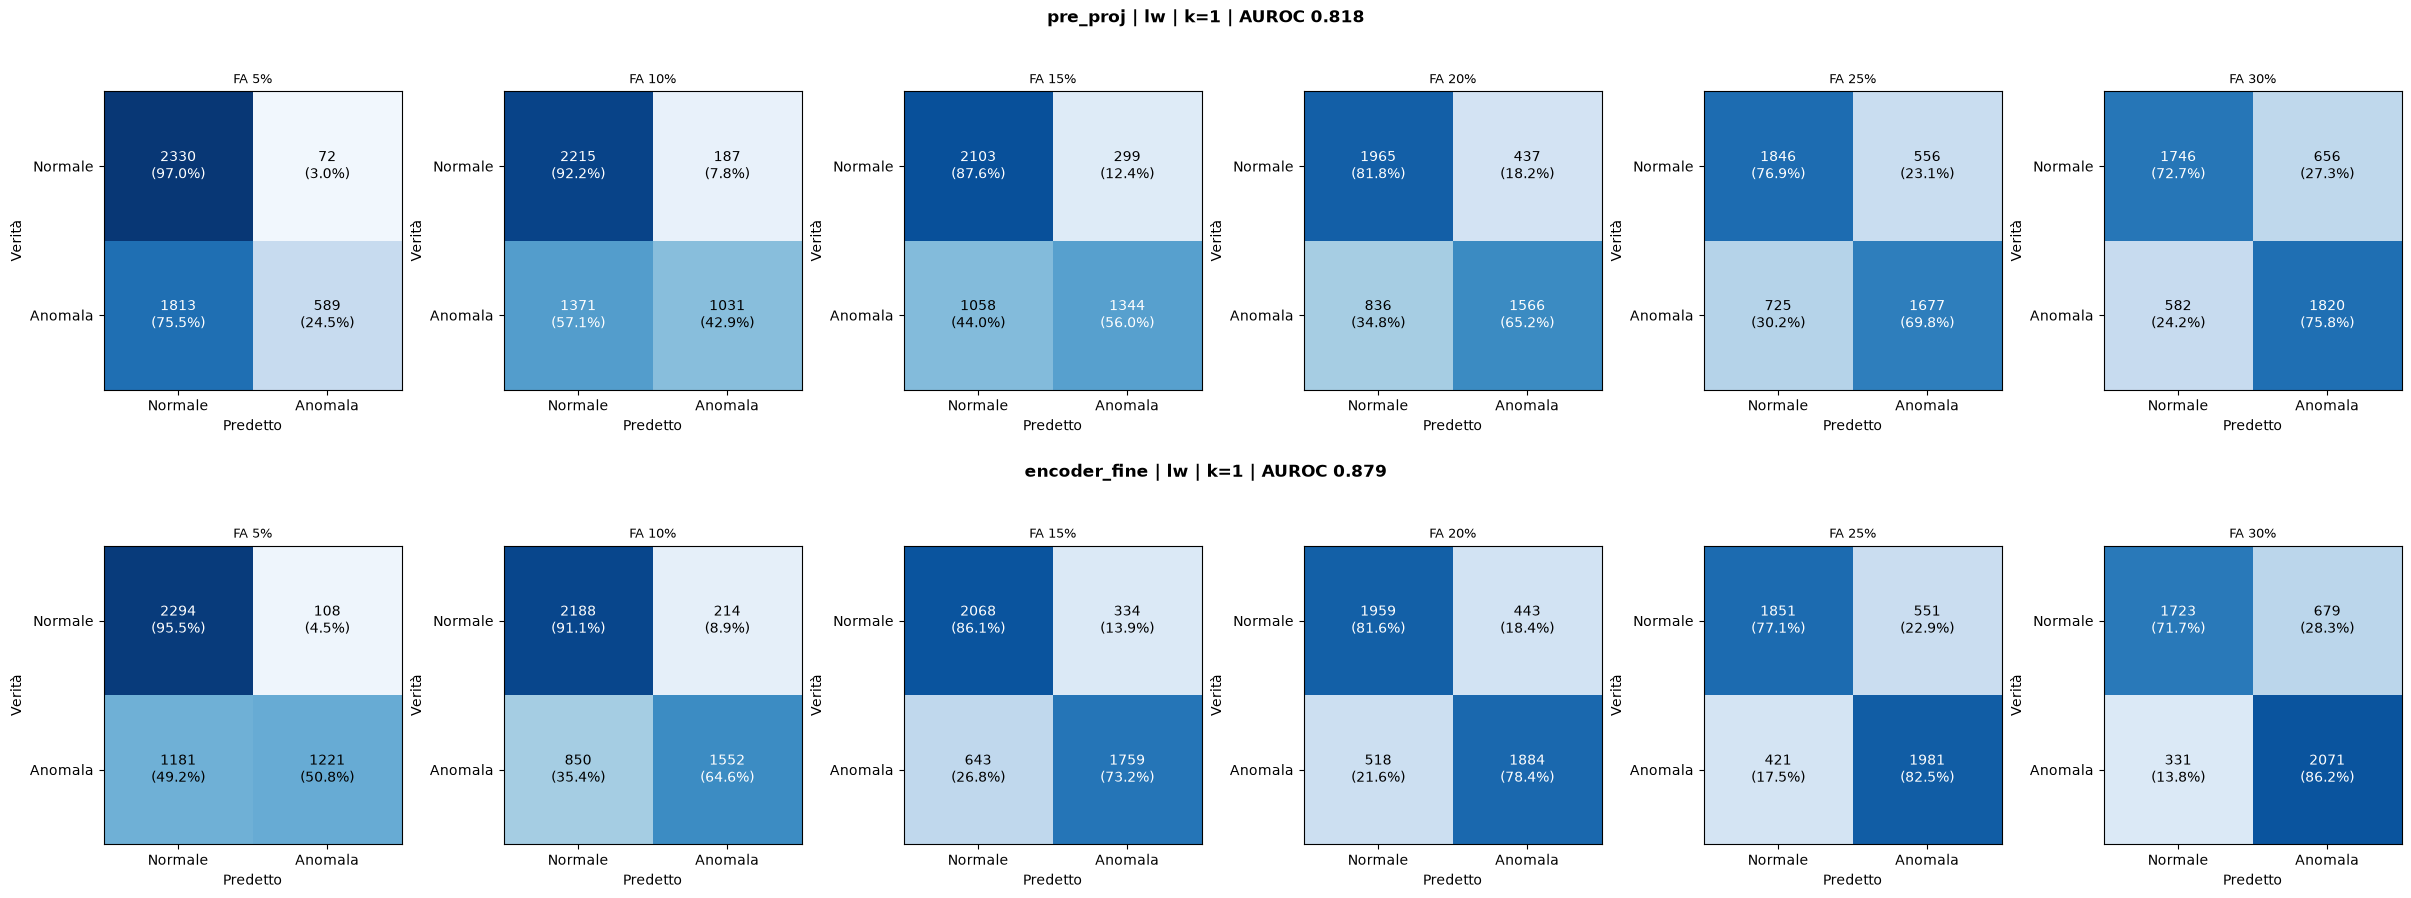

In [ ]:
migliori = tabella.loc[tabella.groupby("punto", sort=False)["AUROC"].idxmax()]
scelte = list(migliori[["punto", "distanza", "k"]].itertuples(index=False, name=None))
print("scelte:", scelte)

singoli, righe = {}, []
for punto, distanza, k in scelte:
    nome = f"{punto} | {distanza} | k={k}"
    with open(f"{RESULTS_DIR}/{punto}/{distanza}/risultati_k{k}.json") as f:
        res = json.load(f)
    test, _, _, s_test = leggi(punto, distanza, k)
    singoli[nome] = (res, s_test, test["label"].values)
    righe.append({"configurazione": nome, "AUROC": res["auroc"], "REC a FA 10%": res["rules"]["FA 10%"]["REC"]})

display(pd.DataFrame(righe).set_index("configurazione").round(3))

fig, axes = plt.subplots(1, len(singoli), figsize=(7 * len(singoli), 5), squeeze=False)
for ax, (nome, (res, s, y_)) in zip(axes[0], singoli.items()):
    plot_istogramma(ax, s, y_, res["rules"], f"{nome} | AUROC {res['auroc']:.3f}", "distanza dai vicini")
plt.tight_layout(); plt.show()

plot_confusioni({nome: (res["rules"], res["auroc"]) for nome, (res, _, _) in singoli.items()})

In [ ]:
from itertools import product

def disponibile(punto, metodo):
    if metodo == "ocsvm":
        return os.path.exists(f"{OCSVM_DIR}/{punto}/scores.csv")
    return os.path.exists(f"{RESULTS_DIR}/{punto}/{metodo}/scores.csv")

metodi = ["coseno", "lw", "ocsvm"]
coppie = [("encoder", "pre_proj", "pre"), ("encoder", "pre_proj_ms", "ms"),
          ("encoder_fine", "pre_proj", "pre"), ("encoder_fine", "pre_proj_ms", "ms"),
          ("encoder_fine", "pre_proj_fine", "pre_fine")]

prove = {}
for p_enc, p_sec, etichetta in coppie:
    for m_enc, m_sec in product(metodi, metodi):
        if disponibile(p_enc, m_enc) and disponibile(p_sec, m_sec):
            prove[f"{p_enc} {m_enc} + {etichetta} {m_sec}"] = {"enc": (p_enc, m_enc), "sec": (p_sec, m_sec)}

print(f"{len(prove)} combinazioni disponibili")

4 combinazioni disponibili


In [ ]:
tab_prove = pd.DataFrame(righe).set_index("combinazione")
migliore = tab_prove["AUROC"].idxmax()            
conf = prove[migliore]
print(f"configurazione scelta: {migliore}")

res = combina(conf)
y, enc = res["y"], res["nomi"][0]
titolo = " + ".join(f"{n} ({conf[n][1]})" for n in conf)
print(f"{titolo}: AUROC {res['auroc']:.3f}")


display(pd.DataFrame(res["rules"]).T.round(3))


tab_rec = pd.DataFrame({"REC encoder": recall_a_fa(y, res["grezzi"][enc]),
                        "REC combinazione": recall_a_fa(y, res["score_test"])},
                       index=[f"FA {fa:.0%}" for fa in FAS])
tab_rec["guadagno"] = tab_rec["REC combinazione"] - tab_rec["REC encoder"]
display(tab_rec.round(3))

fig, ax = plt.subplots(figsize=(8, 5))
plot_istogramma(ax, res["score_test"], y, res["rules"], f"{titolo} | AUROC {res['auroc']:.3f}",
                "score")
plt.tight_layout(); plt.show()

plot_confusioni({titolo: (res["rules"], res["auroc"])})

KeyError: "None of ['combinazione'] are in the columns"

In [ ]:
metodi_knn = ["coseno", "lw"]
ks = [1, 2, 5, 10, 20]

# opzioni per ogni punto: kNN con ogni distanza e ogni k, più l'OC-SVM (senza k)
opzioni = [(d, k) for d in metodi_knn for k in ks] + [("ocsvm", None)]

def etichetta(d, k):
    return d if k is None else f"{d} k{k}"

prove = {
    f"enc {etichetta(*a)} + pre {etichetta(*b)}": {"enc": ("encoder", *a), "pre": ("pre_proj", *b)}
    for a, b in product(opzioni, opzioni)
}
print(len(prove), "combinazioni")      # 11 × 11 = 121

121 combinazioni


In [ ]:
def auroc_split(res, seed=1):
    """AUROC della combinazione sulle due metà delle serie di test (A per scegliere, B per riportare)."""
    y, s = res["y"], res["score_test"]
    idx = np.random.default_rng(seed).permutation(len(y))
    a, b = idx[: len(y) // 2], idx[len(y) // 2:]
    return roc_auc_score(y[a], s[a]), roc_auc_score(y[b], s[b])

righe = []
for nome, conf_p in prove.items():
    r_ = combina(conf_p)
    auc_a, auc_b = auroc_split(r_)
    righe.append({"combinazione": nome, "AUROC A (scelta)": auc_a, "AUROC B (riportato)": auc_b})

tab = pd.DataFrame(righe).set_index("combinazione").sort_values("AUROC A (scelta)", ascending=False)
display(tab.head(10).round(3))
migliore = tab.index[0]
print(f"scelta su A: {migliore} -> AUROC su B {tab.loc[migliore, 'AUROC B (riportato)']:.3f}")

,AUROC A (scelta),AUROC B (riportato)
combinazione,,
enc ocsvm + pre coseno k1,0.881,0.866
enc lw k2 + pre coseno k1,0.881,0.865
enc lw k1 + pre coseno k1,0.881,0.865
enc lw k5 + pre coseno k1,0.880,0.865
enc lw k10 + pre coseno k1,0.880,0.865
enc lw k20 + pre coseno k1,0.880,0.865
enc ocsvm + pre coseno k2,0.880,0.863
enc lw k1 + pre coseno k2,0.879,0.863
enc lw k2 + pre coseno k2,0.879,0.862


scelta su A: enc ocsvm + pre coseno k1 -> AUROC su B 0.866


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.covariance import LedoitWolf
from sklearn.neighbors import NearestNeighbors

def prova_dimensioni(cartella, punto, ks=(32, 64, 128, 256, 512, 1024, 2048),
                     con_lw=True, max_dim_lw=8192, con_knn=True, seed=0):
    """Mahalanobis (e kNN k=1) nello spazio PCA sbiancato con le prime k componenti, contro Ledoit-Wolf completo.
    AUROC su metà delle serie di test (validazione); l'altra metà resta per riportare il risultato."""
    E = np.load(f"{cartella}/{punto}/embeddings.npz")
    cat = lambda g: np.concatenate([E[f"{g}_q"], E[f"{g}_k"]], axis=1).astype(np.float32)
    w = {g: cat(g) for g in ("fit", "thr", "normal", "anom")}
    d = w["fit"].shape[1]
    print(f"{punto}: {d} dimensioni | fit {len(w['fit'])} | normali {len(w['normal'])} | anomale {len(w['anom'])}")

    scaler = StandardScaler().fit(w["fit"])
    w = {g: scaler.transform(v).astype(np.float32) for g, v in w.items()}

    # stesse metà di validazione / test per tutte le prove
    rng = np.random.default_rng(seed)
    ia, i_n = rng.permutation(len(w["anom"])), rng.permutation(len(w["normal"]))
    a_val, n_val = ia[: len(ia) // 2], i_n[: len(i_n) // 2]
    def auroc(s):
        y = np.r_[np.zeros(len(n_val)), np.ones(len(a_val))]
        return roc_auc_score(y, np.r_[s["normal"][n_val], s["anom"][a_val]])

    # PCA solo fino al k più grande che serve: SVD randomizzata, molto più veloce della completa
    k_max = min(max(ks), d, len(w["fit"]) - 1)
    pca = PCA(n_components=k_max, whiten=True, svd_solver="randomized", random_state=seed).fit(w["fit"])
    z = {g: pca.transform(v).astype(np.float32) for g, v in w.items()}
    var_cum = np.cumsum(pca.explained_variance_ratio_)

    righe = []
    for k in ks:
        if k > k_max:
            break
        zk = {g: v[:, :k] for g, v in z.items()}
        riga = {"componenti": k, "varianza spiegata": var_cum[k - 1],
                "Mahalanobis": auroc({g: (v ** 2).sum(1) for g, v in zk.items()})}
        if con_knn:
            nn_ = NearestNeighbors(n_neighbors=1).fit(zk["fit"])
            riga["kNN k=1"] = auroc({g: nn_.kneighbors(zk[g])[0][:, 0] for g in ("normal", "anom")})
        righe.append(riga)
        print(f"  {k:5d} componenti fatte", flush=True)

    if con_lw and d <= max_dim_lw:
        lw = LedoitWolf().fit(w["fit"])
        righe.append({"componenti": f"LW tutte ({d})", "varianza spiegata": 1.0,
                      "Mahalanobis": auroc({g: lw.mahalanobis(v) for g, v in w.items()})})
        print(f"  Ledoit-Wolf shrinkage {lw.shrinkage_:.3f}")
    elif con_lw:
        print(f"  LW saltato: {d} dimensioni > max_dim_lw {max_dim_lw}")

    return pd.DataFrame(righe).set_index("componenti")

In [ ]:
# cartella con gli embedding del job msPre (quella da cui ha letto ad_knn)
cartella = OCSVM_DIR
for punto in ("pre_proj", "pre_proj_fine", "encoder_fine"):
    display(prova_dimensioni(cartella, punto).round(3))

pre_proj: 4096 dimensioni | fit 19893 | normali 2402 | anomale 2402
     32 componenti fatte
     64 componenti fatte
    128 componenti fatte
    256 componenti fatte
    512 componenti fatte
   1024 componenti fatte
   2048 componenti fatte
  Ledoit-Wolf shrinkage 0.011


,varianza spiegata,Mahalanobis,kNN k=1
componenti,,,
32,0.571,0.714,0.767
64,0.657,0.747,0.780
128,0.734,0.761,0.781
256,0.799,0.779,0.789
512,0.858,0.796,0.801
1024,0.915,0.803,0.806
2048,0.968,0.810,0.812
LW tutte (4096),1.000,0.807,NaN


pre_proj_fine: 16384 dimensioni | fit 19893 | normali 2402 | anomale 2402
     32 componenti fatte
     64 componenti fatte
    128 componenti fatte
    256 componenti fatte
    512 componenti fatte
   1024 componenti fatte
   2048 componenti fatte
  LW saltato: 16384 dimensioni > max_dim_lw 8192


,varianza spiegata,Mahalanobis,kNN k=1
componenti,,,
32,0.350,0.689,0.745
64,0.416,0.717,0.746
128,0.486,0.739,0.753
256,0.561,0.744,0.750
512,0.638,0.754,0.758
1024,0.718,0.764,0.765
2048,0.801,0.771,0.770


encoder_fine: 2048 dimensioni | fit 19893 | normali 2402 | anomale 2402


In [ ]:
job_name = "net_v5_msPre_pool8_vec"
RESULTS_DIR = f"/tmp/anomaly_results_knn_{job_name}"
scarica(f"anomaly_results_knn_{job_name}", RESULTS_DIR)
with open(f"{RESULTS_DIR}/summary.json") as f:
    summary = json.load(f)
print("moco:", summary["moco_version"], "| embedding da:", summary["vectors_from"])

moco: net_v5_msPre | embedding da: net_v5_msPre_pool8_vec


In [ ]:
prove_fine = {
    
    "encoder_fine lw + pre msPre lw":        {"enc": ("encoder_fine", "lw", 20), "pre": ("pre_proj", "lw", 1)},
}

for nome, conf_p in prove_fine.items():
    r_ = combina(conf_p)
    g = r_["grezzi"]; n0, n1 = r_["nomi"]
    m, lo, hi = bootstrap_diff(r_["score_test"], g[n0], r_["y"])
    esito = "migliora" if lo > 0 else ("peggiora" if hi < 0 else "nessuna differenza")
    print(f"{nome:40s} | AUROC {r_['auroc']:.3f} | rif {roc_auc_score(r_['y'], g[n0]):.3f} | "
          f"Spearman {spearmanr(g[n0], g[n1]).correlation:.3f} | Δ {m:+.4f} [{lo:+.4f}, {hi:+.4f}] -> {esito}")

encoder_fine lw + pre msPre lw           | AUROC 0.905 | rif 0.883 | Spearman 0.537 | Δ +0.0215 [+0.0150, +0.0283] -> migliora


encoder_fine (lw) + pre_proj msPre (lw): AUROC 0.905 | riferimento encoder_fine 0.883


,soglia,TP,FP,FN,TN,FA_rate,REC,PREC,F1
FA 5%,0.882,1226.0,95.0,1176.0,2307.0,0.040,0.510,0.928,0.659
FA 10%,0.820,1547.0,171.0,855.0,2231.0,0.071,0.644,0.900,0.751
FA 15%,0.756,1800.0,290.0,602.0,2112.0,0.121,0.749,0.861,0.801
FA 20%,0.711,1953.0,414.0,449.0,1988.0,0.172,0.813,0.825,0.819
FA 25%,0.665,2076.0,553.0,326.0,1849.0,0.230,0.864,0.790,0.825
FA 30%,0.638,2154.0,621.0,248.0,1781.0,0.259,0.897,0.776,0.832


,REC encoder_fine,REC combinazione,guadagno
FA 5%,0.481,0.567,0.086
FA 10%,0.649,0.709,0.060
FA 15%,0.739,0.785,0.046
FA 20%,0.795,0.831,0.036
FA 25%,0.846,0.888,0.042
FA 30%,0.884,0.920,0.036


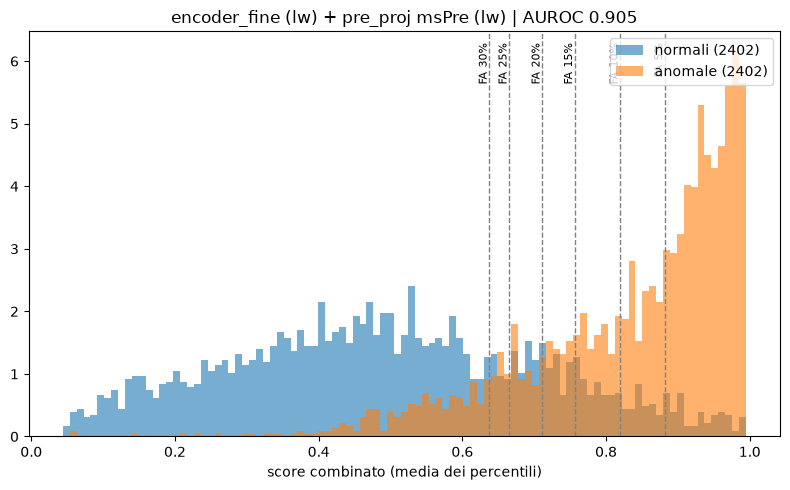

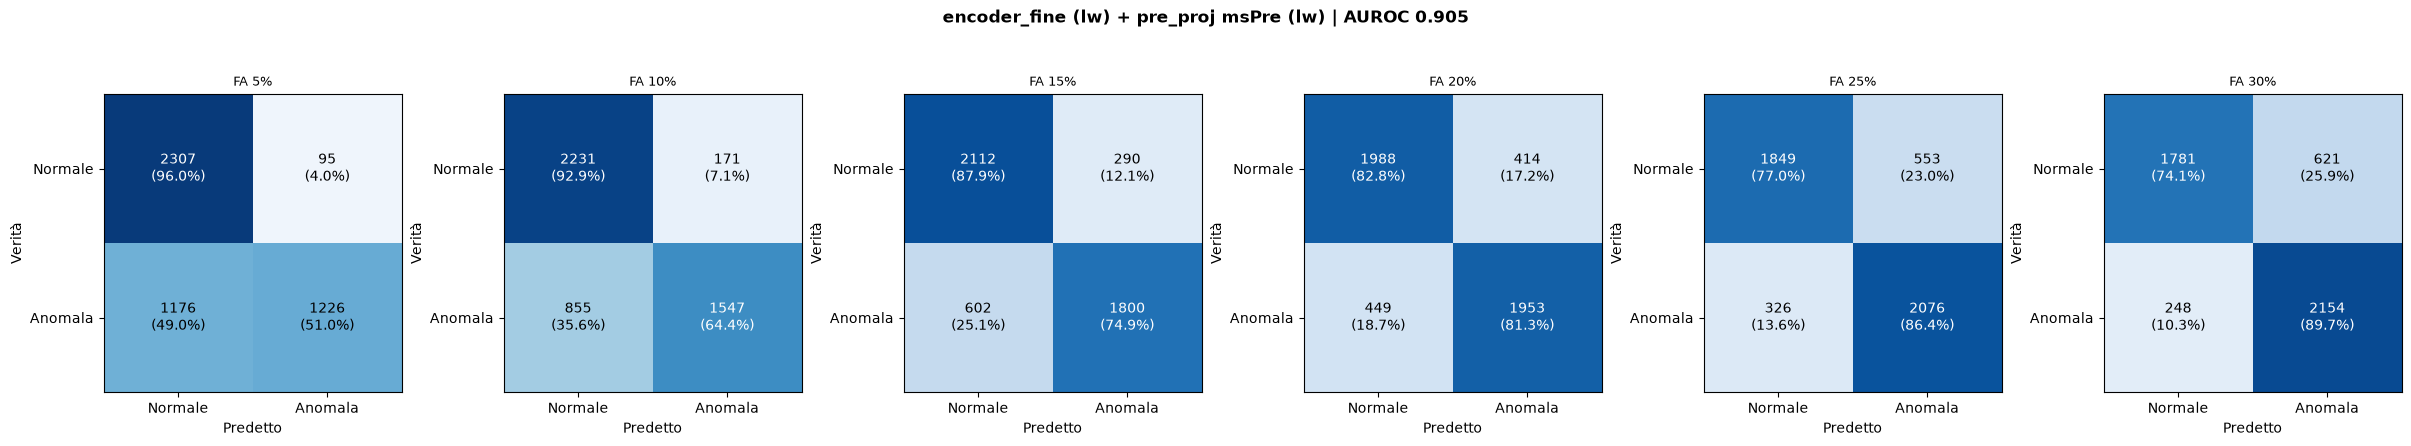

In [ ]:
conf = {"encoder_fine": ("encoder_fine", "lw", 20), "pre_proj_msPre": ("pre_proj", "lw", 1)}

res = combina(conf)
y, enc = res["y"], res["nomi"][0]
titolo = "encoder_fine (lw) + pre_proj msPre (lw)"
print(f"{titolo}: AUROC {res['auroc']:.3f} | riferimento encoder_fine {roc_auc_score(y, res['grezzi'][enc]):.3f}")

# soglie dalle normali di calibrazione
display(pd.DataFrame(res["rules"]).T.round(3))

# recall a falso allarme allineato: encoder_fine da solo vs combinazione
tab_rec = pd.DataFrame({"REC encoder_fine": recall_a_fa(y, res["grezzi"][enc]),
                        "REC combinazione": recall_a_fa(y, res["score_test"])},
                       index=[f"FA {fa:.0%}" for fa in FAS])
tab_rec["guadagno"] = tab_rec["REC combinazione"] - tab_rec["REC encoder_fine"]
display(tab_rec.round(3))

# istogramma con le soglie
fig, ax = plt.subplots(figsize=(8, 5))
plot_istogramma(ax, res["score_test"], y, res["rules"], f"{titolo} | AUROC {res['auroc']:.3f}",
                "score combinato (media dei percentili)")
plt.tight_layout(); plt.show()

# matrici di confusione, una per falso allarme
plot_confusioni({titolo: (res["rules"], res["auroc"])})

In [32]:
import numpy as np, pandas as pd
from sklearn.metrics import roc_curve, roc_auc_score
from scipy.stats import rankdata

# --- 1. le tre cartelle (stesse che hai usato per le tabelle) ---
DIR_ENC8  = "/tmp/anomaly_results_knn_net_v5_msPre_pool8_vec"            # job knn con encoder_fine pool 8
DIR_ENC16 = "/tmp/anomaly_results_knn_net_v5_msPre_pool16_vec"            # job knn con encoder_fine pool 16
DIR_PRE   = "/tmp/anomaly_results_knn_net_v5_msPre_pool8_vec"   # job knn con pre_proj msPre

import glob
for p in sorted(glob.glob("/tmp/anomaly_results_knn_*/*/*/scores.csv")):
    print(p)

def leggi_score(cartella, punto, distanza, k=1):
    df = pd.read_csv(f"{cartella}/{punto}/{distanza}/scores.csv")
    return df[["ID", "label", f"score_k{k}"]].rename(columns={f"score_k{k}": punto})

# --- 2. unisco i tre score per ID, così l'ordine è sicuramente lo stesso ---
e8  = leggi_score(DIR_ENC8,  "encoder_fine", "lw").rename(columns={"encoder_fine": "enc8"})
e16 = leggi_score(DIR_ENC16, "encoder_fine", "lw").rename(columns={"encoder_fine": "enc16"})
pre = leggi_score(DIR_PRE,   "pre_proj",     "lw").rename(columns={"pre_proj": "pre"})
df = e8.merge(e16, on=["ID", "label"]).merge(pre, on=["ID", "label"])
print("serie in comune:", len(df), "| anomalie:", df["label"].sum())

# --- 3. combinazione: media dei ranghi (percentili) di ogni score ---
y = df["label"].values
rango = lambda s: rankdata(s) / len(s)
s8  = (rango(df["enc8"].values)  + rango(df["pre"].values)) / 2
s16 = (rango(df["enc16"].values) + rango(df["pre"].values)) / 2
print(f"AUROC comb 8x8 {roc_auc_score(y, s8):.4f} | comb 16x16 {roc_auc_score(y, s16):.4f}")

# --- 4. bootstrap appaiato: differenza di AUROC e di REC a FA 5% e 10% ---
def rec_a(fa, y, s):
    fpr, tpr, _ = roc_curve(y, s)
    return np.interp(fa, fpr, tpr)

def metriche(y, s):
    return np.array([roc_auc_score(y, s), rec_a(0.05, y, s), rec_a(0.10, y, s)])

rng = np.random.default_rng(0)
idx_n, idx_a = np.where(y == 0)[0], np.where(y == 1)[0]
diffs = []
for _ in range(2000):
    i = np.concatenate([rng.choice(idx_n, len(idx_n)), rng.choice(idx_a, len(idx_a))])
    diffs.append(metriche(y[i], s16[i]) - metriche(y[i], s8[i]))
diffs = np.array(diffs)

oss = metriche(y, s16) - metriche(y, s8)
lo, hi = np.percentile(diffs, [2.5, 97.5], axis=0)
display(pd.DataFrame({"16x16 − 8x8": oss, "IC 2.5%": lo, "IC 97.5%": hi},
                     index=["AUROC", "REC a FA 5%", "REC a FA 10%"]).round(4))

/tmp/anomaly_results_knn_net_v5_msPre_pool16_vec/encoder_fine/coseno/scores.csv
/tmp/anomaly_results_knn_net_v5_msPre_pool16_vec/encoder_fine/lw/scores.csv
/tmp/anomaly_results_knn_net_v5_msPre_pool16_vec/pre_proj/coseno/scores.csv
/tmp/anomaly_results_knn_net_v5_msPre_pool16_vec/pre_proj/lw/scores.csv
/tmp/anomaly_results_knn_net_v5_msPre_pool8_vec/encoder/coseno/scores.csv
/tmp/anomaly_results_knn_net_v5_msPre_pool8_vec/encoder/lw/scores.csv
/tmp/anomaly_results_knn_net_v5_msPre_pool8_vec/encoder_fine/coseno/scores.csv
/tmp/anomaly_results_knn_net_v5_msPre_pool8_vec/encoder_fine/lw/scores.csv
/tmp/anomaly_results_knn_net_v5_msPre_pool8_vec/pre_proj/coseno/scores.csv
/tmp/anomaly_results_knn_net_v5_msPre_pool8_vec/pre_proj/lw/scores.csv
/tmp/anomaly_results_knn_net_v5_msPre_pool8_vec/pre_proj_fine/coseno/scores.csv
/tmp/anomaly_results_knn_net_v5_msPre_pool8_vec/pre_proj_fine/lw/scores.csv
serie in comune: 4804 | anomalie: 2402
AUROC comb 8x8 0.9027 | comb 16x16 0.9078


,16x16 − 8x8,IC 2.5%,IC 97.5%
AUROC,0.0051,0.0012,0.0090
REC a FA 5%,0.0275,-0.0062,0.0570
REC a FA 10%,0.0296,0.0017,0.0515


In [ ]:
import numpy as np, glob
from sklearn.metrics import roc_auc_score

print(glob.glob("/tmp/anomaly_results_ocsvm_net_v5_msPre_ep10/post_proj/embeddings.npz"))   # cerca un job che lo abbia
d = np.load(".../post_proj/embeddings.npz")
print(d.files)                       # guarda come si chiamano le chiavi del test (embedding e label)

X, y = d["X_test"], d["y_test"]      # <- sostituisci con i nomi veri
q, k = X[:, :128], X[:, 128:]        # verifica nell'handler l'ordine di torch.cat: (q, k) o (k, q)
q /= np.linalg.norm(q, axis=1, keepdims=True)
k /= np.linalg.norm(k, axis=1, keepdims=True)
score = 1 - (q * k).sum(1)           # disaccordo: alto = ottico e SAR non concordano
print("AUROC disaccordo:", roc_auc_score(y, score))

In [36]:
import numpy as np, glob
from sklearn.metrics import roc_auc_score

print(glob.glob("/tmp/anomaly_results_ocsvm_net_v5_msPre_ep10/post_proj/embeddings.npz"))   # cerca un job che lo abbia

[]


In [40]:
import numpy as np, torch, glob
from sklearn.metrics import roc_auc_score, roc_curve

d = np.load("/tmp/anomaly_results_ocsvm_net_v5_msPre_pool8_vec/pre_proj_fine/embeddings.npz")

G, C = 8, 128                                    # griglia e canali per modalità
def a_riquadri(q, k):
    # (N, 16*16*16) per modalità -> (N, 256, 16), poi ottico e SAR affiancati -> (N, 256, 32)
    q = q.reshape(len(q), C, G * G).transpose(0, 2, 1)
    k = k.reshape(len(k), C, G * G).transpose(0, 2, 1)
    return np.concatenate([q, k], axis=2).astype(np.float32)

F = a_riquadri(d["fit_q"], d["fit_k"])                                   # banca: normali di fit
T = a_riquadri(np.concatenate([d["normal_q"], d["anom_q"]]),
               np.concatenate([d["normal_k"], d["anom_k"]]))             # test
y   = np.r_[np.zeros(len(d["normal_ids"])), np.ones(len(d["anom_ids"]))]
ids = np.r_[d["normal_ids"], d["anom_ids"]]                              # servirà per combinare con pre_proj
M = 2                                                                    # per i punti successivi: 2 modalità
print(F.shape, T.shape, y.mean())    # atteso: (19893, 256, 32) (4804, 256, 32) 0.5

# 3. banca: un campione casuale di riquadri normali
rng = np.random.default_rng(0)
tutti = F.reshape(-1, M * C)
banca = torch.tensor(tutti[rng.choice(len(tutti), min(100_000, len(tutti)), replace=False)])
banca2 = (banca ** 2).sum(1)

def distanza_minima(Q):                           # Q: (n, 32) -> distanza dal riquadro normale più vicino
    Q = torch.tensor(Q)
    d2 = (Q ** 2).sum(1, keepdim=True) - 2 * Q @ banca.T + banca2
    return d2.min(1).values.clamp_min(0).sqrt().numpy()

# 4. score di ogni riquadro del test (a blocchi di 8 serie per non riempire la RAM)
dist = np.empty(T.shape[:2], dtype=np.float32)
for i in range(0, len(T), 8):
    b = T[i:i + 8]
    dist[i:i + 8] = distanza_minima(b.reshape(-1, M * C)).reshape(b.shape[:2])

# 5. dal riquadro alla serie: tre modi di aggregare
def rec_a(fa, y, s):
    fpr, tpr, _ = roc_curve(y, s); return np.interp(fa, fpr, tpr)

for nome, s in {"max": dist.max(1),
                "media top-5": np.sort(dist, 1)[:, -5:].mean(1),
                "media": dist.mean(1)}.items():
    print(f"{nome:12s} AUROC {roc_auc_score(y, s):.4f} | REC FA5% {rec_a(.05, y, s):.3f} | REC FA10% {rec_a(.10, y, s):.3f}")

(19893, 64, 256) (4804, 64, 256) 0.5
max          AUROC 0.7537 | REC FA5% 0.178 | REC FA10% 0.303
media top-5  AUROC 0.7718 | REC FA5% 0.197 | REC FA10% 0.341
media        AUROC 0.7834 | REC FA5% 0.277 | REC FA10% 0.441


In [39]:
import numpy as np, torch, glob
from sklearn.metrics import roc_auc_score, roc_curve

d = np.load("/tmp/anomaly_results_ocsvm_net_v5_msPre_pool16_vec/encoder_fine/embeddings.npz")

G, C = 16, 16                                    # griglia e canali per modalità
def a_riquadri(q, k):
    # (N, 16*16*16) per modalità -> (N, 256, 16), poi ottico e SAR affiancati -> (N, 256, 32)
    q = q.reshape(len(q), C, G * G).transpose(0, 2, 1)
    k = k.reshape(len(k), C, G * G).transpose(0, 2, 1)
    return np.concatenate([q, k], axis=2).astype(np.float32)

F = a_riquadri(d["fit_q"], d["fit_k"])                                   # banca: normali di fit
T = a_riquadri(np.concatenate([d["normal_q"], d["anom_q"]]),
               np.concatenate([d["normal_k"], d["anom_k"]]))             # test
y   = np.r_[np.zeros(len(d["normal_ids"])), np.ones(len(d["anom_ids"]))]
ids = np.r_[d["normal_ids"], d["anom_ids"]]                              # servirà per combinare con pre_proj
M = 2                                                                    # per i punti successivi: 2 modalità
print(F.shape, T.shape, y.mean())    # atteso: (19893, 256, 32) (4804, 256, 32) 0.5

# 3. banca: un campione casuale di riquadri normali
rng = np.random.default_rng(0)
tutti = F.reshape(-1, M * C)
banca = torch.tensor(tutti[rng.choice(len(tutti), min(100_000, len(tutti)), replace=False)])
banca2 = (banca ** 2).sum(1)

def distanza_minima(Q):                           # Q: (n, 32) -> distanza dal riquadro normale più vicino
    Q = torch.tensor(Q)
    d2 = (Q ** 2).sum(1, keepdim=True) - 2 * Q @ banca.T + banca2
    return d2.min(1).values.clamp_min(0).sqrt().numpy()

# 4. score di ogni riquadro del test (a blocchi di 8 serie per non riempire la RAM)
dist = np.empty(T.shape[:2], dtype=np.float32)
for i in range(0, len(T), 8):
    b = T[i:i + 8]
    dist[i:i + 8] = distanza_minima(b.reshape(-1, M * C)).reshape(b.shape[:2])

# 5. dal riquadro alla serie: tre modi di aggregare
def rec_a(fa, y, s):
    fpr, tpr, _ = roc_curve(y, s); return np.interp(fa, fpr, tpr)

for nome, s in {"max": dist.max(1),
                "media top-5": np.sort(dist, 1)[:, -5:].mean(1),
                "media": dist.mean(1)}.items():
    print(f"{nome:12s} AUROC {roc_auc_score(y, s):.4f} | REC FA5% {rec_a(.05, y, s):.3f} | REC FA10% {rec_a(.10, y, s):.3f}")

(19893, 256, 32) (4804, 256, 32) 0.5
max          AUROC 0.8376 | REC FA5% 0.348 | REC FA10% 0.528
media top-5  AUROC 0.8564 | REC FA5% 0.405 | REC FA10% 0.583
media        AUROC 0.8425 | REC FA5% 0.450 | REC FA10% 0.561
